In [100]:
from typing import Annotated, Literal
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages
from pydantic import BaseModel, Field
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph, START, END
from langchain_core.tools import tool
from langchain.agents import create_agent
from dotenv import load_dotenv

load_dotenv()

True

In [101]:
model = ChatGroq(model="openai/gpt-oss-safeguard-20b")

In [102]:
@tool
def addition(a:int , b:int):
    """Use this tools for addition"""
    return a+b

@tool
def subtraction(a:int , b:int):
    """Use this tools for subtraction"""
    return a-b


agent_a=create_agent(
    model=model,
    tools=[addition],
    system_prompt="You are exprert in performing addition"

)

agent_b=create_agent(
    model=model,
    tools=[subtraction],
    system_prompt="You are exprert in performing subtraction"

)

In [103]:
class State(TypedDict):
    messages: Annotated[list,add_messages]
    intent: str



class IntentSchema(BaseModel):
    intent: Literal["subtraction","addition"]=Field(description="Just determine the user intent whether he wants to add or sutract two numbers")


router_model = model.with_structured_output(IntentSchema)

In [104]:
def router_node(state:State):
    last_message=state["messages"][-1]
    result = router_model.invoke([last_message])
    return {"intent":result.intent}


def addition(state):
    result = agent_a.invoke(
        {"messages": state["messages"]}
    )
    return {"messages": result["messages"]}


def subtraction(state):
    result = agent_b.invoke(
        {"messages": state["messages"]}
    )
    return {"messages": result["messages"]}

def route(state:State):
    return state["intent"]

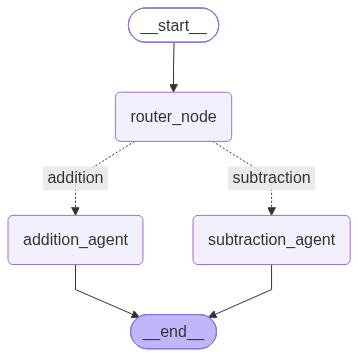

In [105]:
graph=StateGraph(State)
graph.add_node("router_node",router_node)
graph.add_node("addition_agent",addition)
graph.add_node("subtraction_agent",subtraction)

graph.add_edge(START,"router_node")
graph.add_conditional_edges("router_node",route,
                            {
                                "addition": "addition_agent",
                                "subtraction": "subtraction_agent"                                
                            })
graph.add_edge("addition_agent",END)
graph.add_edge("subtraction_agent",END)

graph=graph.compile()
graph

In [106]:
init_state={"messages": [HumanMessage(content="I want to sub 2 and 2")]}


In [107]:
result=graph.invoke(init_state)

In [108]:
result["messages"][-1].content

'The result of subtracting 2 from 2 is **0**.'